# Переносится ли преобразование масштаба в пространстве CLS?

Для каждого изображения есть два реальных выхода замороженной сети — до и после увеличения. Учим внешнюю функцию предсказывать второй вектор по первому. Проверяем отдельно **перенос на новый объект** и **экстраполяцию на новый коэффициент увеличения**. На фотографии и рукописные цифры оператор переносится без подгонки. Идея измерять эквивариантность через предсказание признаков восходит к работе [Lenc и Vedaldi](https://www.robots.ox.ac.uk/~vedaldi/assets/pubs/lenc15understanding.pdf).

**Что видела сеть.** Основная модель `big_10` — DeiT-Tiny из этого репозитория, seed 42. При обучении она видела все 26 букв Times New Roman высотой 64 px и десять из них (`ABCDEFGIJK`) также при 128 px. Веса фиксированы. Снимаем 192 координаты CLS после каждого из 12 блоков и после финального LayerNorm. Последний вектор поступает в линейный классификатор.

**Что видел оператор.** В решающем сравнении обе карты получают одни и те же 120 исходных изображений — 10 донорских букв по 12 положений. Одной показываем пары 64→96, другой — 64→128. Проверка всегда одна и та же — 64→128, 16 остальных букв × 12 других положений для каждого шрифта. Центр и смещение изображения в каждой паре согласованы, символ целиком в кадре. Все тестовые положения новые для оператора. Для самой сети все 12 отсутствовали в обучении на малых буквах, 8 из 12 входили в пул обучения на больших донорах.

**Внешняя проверка.** В [COIL-20](https://www.cs.columbia.edu/CAVE/software/softlib/coil-20.php) взяты 20 физических предметов по 8 ракурсов. В [MNIST](https://github.com/cvdfoundation/mnist) — по 20 тестовых экземпляров каждой цифры. Сторону одного и того же исходного кадра меняем с 64 до 128 px на чёрном холсте 224 × 224 в четырёх положениях. У букв задаём высоту видимого символа. У фотографий и цифр задаём сторону кадра с сохранением его внутренних полей.

## Метрика и контрольные модели

Для вектора \(z_h\) при высоте \(h\) исходное предсказание равно \(z_{64}\). Выигрыш карты \(T\) на тестовых парах равен

$$ S=1-\frac{\sum_i\|T(z_{64,i})-z_{128,i}\|_2^2}{\sum_i\|z_{64,i}-z_{128,i}\|_2^2}. $$

\(S=0{,}23\) означает снижение суммарной квадратичной ошибки на 23% относительно сохранения исходного вектора. Отрицательное значение означает рост ошибки. В центрированной версии из векторов ошибок вычитается их среднее по объектам для каждого положения отдельно. Это убирает из оценки общий для всех объектов сдвиг. Обе версии используют одни и те же предсказания.

- **Ridge** оценивает аффинную зависимость изменения CLS от исходного CLS с L2-регуляризацией. При переносе между коэффициентами предсказанное изменение пропорционально \(\log(h_2/h_1)\).
- **Shear-4** ограничивает зависящую от входа часть изменения четырьмя направлениями. Для \(T_t(z)=z+t\,v(z)\) накладывается условие \(v(T_t(z))=v(z)\). Тогда \(T_s(T_t(z))=T_{s+t}(z)\) при логарифмическом параметре масштаба. Это узкое семейство операторов с прямыми траекториями. Общее матричное экспоненцирование допускает и кривые траектории.
- **Геометрический контроль** прогнозирует добавку к исходному CLS только по суммарной яркости и числу непустых патчей 16 × 16 исходного изображения. В CSV также есть общий сдвиг, свободный оператор по четырём направлениям и контроль с перемешанным соответствием донорских классов.

In [1]:
import csv
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "experiments/scale_operator.py").is_file():
    root = root.parent
sys.path.insert(0, str(root / "experiments"))
from scale_operator import DONORS, calibration_control, fit_operators, squared_errors

import matplotlib.pyplot as plt
import numpy as np

results = root / "results/scale_operator"

def read_rows(name):
    with (results / name).open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

with np.load(root / "data/scale_operator/big_10_ln.npz", allow_pickle=False) as pack:
    features = pack["features"]
    logits = pack["logits"]
    letters = pack["letters"]
    heights = pack["heights"]
    refit = calibration_control("big_10", features, pack["ink_mass"], pack["occupied_patches"])

def fit_key(row):
    return row["test_font"], int(row["fit_h2"]), row["method"]

saved = {fit_key(r): r for r in read_rows("operator_calibration.csv") if r["model"] == "big_10"}
assert {fit_key(r) for r in refit} == set(saved)
for row in refit:
    reference = saved[fit_key(row)]
    for field in ("skill", "centered_skill", "letters_improved"):
        np.testing.assert_allclose(row[field], float(reference[field]), atol=1e-7)
print(f"Воспроизведены {len(refit)} оценок по финальному CLS на CPU.")

Воспроизведены 28 оценок по финальному CLS на CPU.


In [2]:
external = read_rows("external_calibration.csv")
domain_keys = {"COIL-20": "coil", "MNIST": "mnist"}
with np.load(root / "data/scale_operator/external_big_10_ln.npz", allow_pickle=False) as pack:
    fits = {h: fit_operators(features, pairs=((64, h),)) for h in (96, 128)}
    for domain, key in domain_keys.items():
        frames = pack[key + "_features"]
        x, y = frames[:, 0], frames[:, 1]
        for h, operators in fits.items():
            loss, center = squared_errors(x, y, operators["ridge"], 64, 128)
            base, base_center = squared_errors(x, y, operators["identity"], 64, 128)
            estimate = [1 - loss.sum() / base.sum(), 1 - center.sum() / base_center.sum()]
            row, = [r for r in external if r["model"] == "big_10" and r["dataset"] == domain
                    and r["group"] == "all" and r["method"] == "ridge" and int(r["fit_h2"]) == h]
            np.testing.assert_allclose(estimate, [float(row["skill"]), float(row["centered_skill"])],
                                       atol=1e-7)
print("Пересчитан выигрыш ridge на фотографиях и цифрах для обеих калибровок.")

Пересчитан выигрыш ridge на фотографиях и цифрах для обеих калибровок.


Тест 64→128       Ridge ×1,5    Ridge ×2   Shear-4 ×2   Геометрия ×2
Times New Roman       -30.4%      +23.3%       +5.0%       +4.6%
Arial                -127.7%      +24.5%       +7.7%       +5.0%
COIL-20               -65.0%       +7.8%       +0.2%       +1.4%
MNIST                 -87.9%      +12.9%       +3.6%       -0.9%


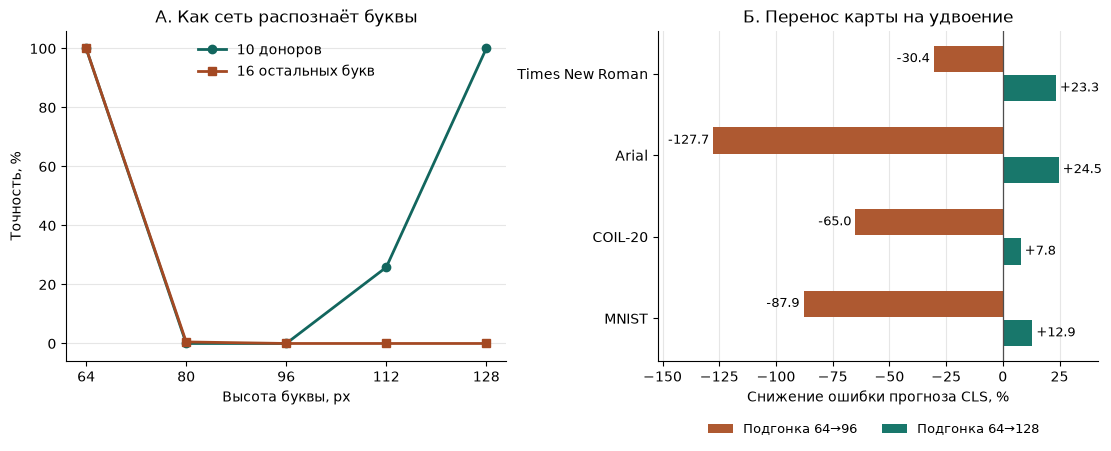

In [3]:
scores = {(r["test_font"], int(r["fit_h2"]), r["method"]): float(r["skill"]) for r in refit}
for r in external:
    if r["model"] == "big_10" and r["group"] == "all":
        scores[r["dataset"], int(r["fit_h2"]), r["method"]] = float(r["skill"])

domains = ["Times New Roman", "Arial", "COIL-20", "MNIST"]
print(f"{'Тест 64→128':16} {'Ridge ×1,5':>11} {'Ridge ×2':>11} {'Shear-4 ×2':>12} {'Геометрия ×2':>14}")
for domain in domains:
    print(f"{domain:16}", *(f"{scores[domain, h, method]:+11.1%}" for h, method in
                             [(96, "ridge"), (128, "ridge"), (128, "shear4"), (128, "footprint")]))

donor = np.isin(letters, list(DONORS))
correct = logits[:, 0, :, 12:].argmax(-1) == np.arange(26)[:, None, None]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
for mask, label, color, marker in [(donor, "10 доноров", "#12665e", "o"),
                                  (~donor, "16 остальных букв", "#a44923", "s")]:
    left.plot(heights, 100 * correct[mask].mean(axis=(0, 2)), marker=marker, lw=2,
              color=color, label=label)
left.set(title="А. Как сеть распознаёт буквы", xlabel="Высота буквы, px", ylabel="Точность, %",
         xticks=heights, ylim=(-6, 106))
left.legend(frameon=False, loc="upper center")
y = np.arange(len(domains))
for h, offset, color, label in [(96, -0.18, "#ae5931", "Подгонка 64→96"),
                                (128, 0.18, "#18776b", "Подгонка 64→128")]:
    vals = [100 * scores[domain, h, "ridge"] for domain in domains]
    bars = right.barh(y + offset, vals, height=0.32, color=color, label=label)
    right.bar_label(bars, labels=[f"{v:+.1f}" for v in vals], padding=3, fontsize=9)
right.axvline(0, color="0.3", lw=0.9)
right.set(title="Б. Перенос карты на удвоение", yticks=y, yticklabels=domains,
          xlim=(-152, 42), xlabel="Снижение ошибки прогноза CLS, %")
right.invert_yaxis()
right.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.49, -0.15), ncol=2)
for ax in (left, right):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y" if ax is left else "x", color="0.9")
    ax.set_axisbelow(True)
fig.savefig(results / "scale_transfer.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

У доноров точность на высотах 64, 80, 96, 112 и 128 составила **120, 0, 0, 31 и 120 из 120**. Даже на той же букве в той же позиции распознавание двух знакомых размеров допускает полный провал посередине.

При калибровке на удвоение ridge снизила ошибку для всех 16 отложенных букв обоих шрифтов, для 14 из 20 предметов и для всех 10 групп цифр. После удаления общего сдвига выигрыш сохранился (Times +22,2%, Arial +21,5%, COIL-20 +11,3%, MNIST +9,7%). Это свидетельство переноса части преобразования CLS за пределы донорских букв. Контроль по двум признакам размера дал существенно меньший выигрыш. Другие свойства растрового изображения по этому сравнению исключить нельзя.

**Выучила ли сеть этот перенос при обучении на донорах?** Проверяем той же процедурой две контрольные сети — со случайными весами (`initial`, seed 42) и обученную только на малых буквах (`big_00`). Для каждой сети карту отдельно подгоняем по её активациям.

In [4]:
print("COIL-20, калибровка на удвоение, финальный CLS")
print("Модель       Ridge     Ridge после центрирования    Общий сдвиг")
for model in ("initial", "big_00", "big_10"):
    selected = {r["method"]: r for r in external if r["model"] == model and r["dataset"] == "COIL-20"
                and r["group"] == "all" and int(r["fit_h2"]) == 128}
    ridge, drift = selected["ridge"], selected["drift"]
    print(f"{model:8} {float(ridge['skill']):+10.1%} {float(ridge['centered_skill']):+23.1%}"
          f" {float(drift['skill']):+18.1%}")

COIL-20, калибровка на удвоение, финальный CLS
Модель       Ridge     Ridge после центрирования    Общий сдвиг
initial      +91.2%                  +43.7%             +81.9%
big_00       +20.9%                  +47.9%             -38.1%
big_10        +7.8%                  +11.3%              -0.7%


На фотографиях даже после удаления общего сдвига ridge дала +43,7% у случайной сети, +47,9% у обученной только на малых буквах и +11,3% у сети с десятью донорами. Каждое число нормировано на ошибку тождественной карты **той же сети**. Это сравнение измеряет доступность преобразования для выбранной карты. Оно показывает, что для положительного результата достаточно и необученной сети. Приписывать выигрыш обучению на крупных донорах по этим данным оснований нет.

## Где простая модель масштаба ломается

Есть отдельная подгонка на трёх переходах в пределах 64–96 px (64→80, 80→96, 64→96). Измеряем экстраполяцию на 64→128 по глубине сети для тех же 16 отложенных букв Times. Дополнительно проверяем геометрическое следствие Shear-4 на наблюдаемых выходах финального слоя. При точном действии такой карты две последовательные ненулевые хорды одной траектории должны смотреть в одном направлении.

In [5]:
depth = [r for r in read_rows("operator_scores.csv")
         if (r["model"], r["font"], r["h1"], r["h2"], r["method"]) ==
            ("big_10", "Times New Roman", "64", "128", "shear4")]
print("Слой      общий S     центрированный S")
for r in depth:
    print(f"{r['layer']:5} {float(r['skill']):+10.1%} {float(r['centered_skill']):+17.1%}")

z = features[:, 0, :, 12:].astype(float)
first = z[:, 2] - z[:, 0]   # 64 → 96
second = z[:, 4] - z[:, 2]  # 96 → 128
cosine = (first * second).sum(-1) / (np.linalg.norm(first, axis=-1) * np.linalg.norm(second, axis=-1))
for mask, label in [(donor, "Доноры"), (~donor, "Остальные")]:
    c = cosine[mask]
    print(f"{label}: медиана косинуса {np.median(c):+.3f}, отрицательных {np.sum(c < 0)}/{c.size}")

Слой      общий S     центрированный S
B1        +16.1%             -0.0%
B2        +17.5%             +0.1%
B3        +19.5%             -1.0%
B4         -4.2%            -10.8%
B5        -22.2%            -23.1%
B6        -23.9%            -27.3%
B7        -36.1%            -27.6%
B8        -47.5%            -44.6%
B9        -59.5%            -62.0%
B10       -73.2%            -72.4%
B11       -88.8%            -63.1%
B12       -91.7%            -61.3%
LN       -128.9%            -70.5%
Доноры: медиана косинуса -0.926, отрицательных 120/120
Остальные: медиана косинуса -0.520, отрицательных 192/192


У Shear-4 в первых трёх блоках общий выигрыш 16–19%, а центрированный — около нуля. После финального LayerNorm ошибка в 2,29 раза выше исходной. Для сравнения, у модели со случайными весами на финальном слое общий выигрыш +77,1%, но центрированный −5,0%. Сильный общий сдвиг представлений возможен до обучения классификатора.

В финальном CLS два приращения имеют отрицательное скалярное произведение на всех проверенных положениях. Точное прямолинейное движение в одну сторону несовместимо с такими тройками. Обе хорды содержат среднюю точку с противоположными знаками, поэтому отрицательный косинус сам по себе слабо диагностирует причину изгиба. Этот тест оставляет открытым вопрос о нелинейном действии масштаба и о механизме в патч-токенах.

## Помогает ли вмешательство классификации?

На реально отрисованных больших буквах сравниваем исходный прогноз с двумя вмешательствами. Первое применяет к CLS обратную карту Shear-4 из диапазона 64–96 перед замороженной головой. Второе находит границы непустых пикселей, приводит высоту глифа к 64 и прогоняет изображение через ту же сеть. Границы вычисляются без меток. Чёрный фон делает такое измерение доступным.

In [6]:
readout = read_rows("readout.csv")
for font in ["Times New Roman", "Arial"]:
    rows = [r for r in readout if r["model"] == "big_10" and r["height"] == "128"
            and r["font"] == font and r["probe_fit"] == "False"]
    print(font)
    for method in ["original", "shear4", "bbox_to_64"]:
        selected = [r for r in rows if r["method"] == method]
        print(f"  {method:11} {sum(int(r['correct']) for r in selected)}/{sum(int(r['n']) for r in selected)}")

Times New Roman
  original    0/192
  shear4      0/192
  bbox_to_64  192/192
Arial
  original    0/192
  shear4      0/192
  bbox_to_64  51/192


**Вывод.** Для знакомого шрифта нормализация до патчификации вернула точность на больших отложенных буквах с 0/192 до 192/192. В Arial она восстановила 51/192. Это показывает, что классификатор способен решить задачу после коррекции входа и что смена шрифта добавляет отдельную трудность. Место возникновения ошибки внутри сети остаётся открытым.

Полученный положительный результат относится к **предсказанию признаков при знакомом коэффициенте**. Для экстраполяции и для исправления ответа классификатора нужны отдельные проверки. Ограничения — одна инициализация, один набор доноров в основном сравнении, изолированные объекты и цифровое увеличение одного кадра. Положения и ракурсы одного предмета зависимы. По этому исследовательскому сравнению нельзя устанавливать оптимальность архитектуры или делать вывод обо всех ViT.

Следующий различающий тест — повторить тот же протокол на предобученном на естественных изображениях ViT, отложив экземпляры, категории и коэффициенты масштаба, и сравнить CLS с пространственно согласованными патч-токенами. Это позволит проверить, где сохраняется перенос при смене тренировочной задачи.

## Воспроизведение

Для запуска этого ноутбука нужны NumPy и Matplotlib в ядре Python. Компактный архив финального CLS содержит активации, логиты, признаки заполнения, смещения и контрольные суммы исходных файлов. По нему заново оцениваются карты на буквах. Второй компактный архив содержит парные активации финального слоя для фотографий и рукописных цифр. Ноутбук независимо повторяет для них обе калибровки ridge и сверяет результат с CSV. Остальные слои и контрольные сети представлены готовыми таблицами.

Полный прогон из корня проекта использует PyTorch с CUDA, Pillow, шрифты `times.ttf`, `arial.ttf` (каталог можно задать в `SCALE_FONT_DIR`), сохранённый `data/letters.pt` и локальные веса `big_00.pt`, `big_10.pt` из `results/letters_scale_val100`. [Ноутбук обучения](letters_training.ipynb) продолжает обучение из исходных локальных чекпойнтов. Опубликованные архивы позволяют проверить основные результаты без весов. Скрипт внешней проверки сверяет SHA-256 скачанных файлов.

```sh
python experiments/scale_features.py
python experiments/scale_operator.py
python experiments/scale_readout.py
python experiments/transfer_objects.py --download
```